# RK4はなぜ4次精度なのか

## 概要
古典的な4段4次Runge–Kutta法（RK4）が4次精度になる理由を、厳密解と各段のTaylor展開から確認する。1ステップの誤差が$O(h^5)$、固定区間での誤差が$O(h^4)$になる過程を示し、Pythonで収束次数を調べる。線形方程式に加え、非線形方程式と連立方程式も扱う。

## 実行環境
仮想環境・カーネルの表示名は`wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SymPy、Matplotlibを使う。以下で実際のバージョンを表示する。作業ディレクトリはこのノートブックのある場所とし、図は`106_nb_files`にSVGで保存する。表示する小数は有効数字3桁とし、内部の計算は丸めない。

In [1]:
import platform
from pathlib import Path
from pprint import pprint

import numpy as np
import sympy as sp
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from IPython.display import Latex, display

%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
# 図のファイルはSVGとし、ノートブックには互換表示用のPNGも埋め込む。
set_matplotlib_formats("svg", "png")

assert platform.python_version() == "3.14.6"
print("環境: wa-src(3.14.6)")
print("Python:", platform.python_version())
for package in (np, sp, matplotlib):
    print(package.__name__, package.__version__)

image_dir = Path("106_nb_files")
image_dir.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "figure.figsize": (10, 4)})


def sig3(value):
    """表示だけを有効数字3桁にする。"""
    if value == 0:
        return "0"
    if abs(value) < 0.0100 or abs(value) >= 1000:
        return f"{value:.2e}"
    return f"{float(value):#.3g}".removesuffix(".")


np.set_printoptions(formatter={"float_kind": sig3})


def save_plot(fig, name):
    """目盛りを整えて、同じ図をSVG保存とノートブック表示に使う。"""
    for ax in fig.axes:
        ax.grid(alpha=0.300)
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda x, pos: sig3(x)))
            axis.set_minor_formatter(NullFormatter())
    fig.tight_layout()
    fig.savefig(image_dir / f"{name}.svg", format="svg")
    plt.show()
    plt.close(fig)

環境: wa-src(3.14.6)
Python: 3.14.6
numpy 2.5.4
sympy 1.14.0
matplotlib 3.11.2


## 1. RK4の更新式
初期値問題$\mathbf y'=\mathbf f(t,\mathbf y)$を、刻み幅$h$で計算する。$\mathbf y_n$は時刻$t_n$の近似値であり、各段$\mathbf k_i$は傾きである。ここでは$\mathbf k_i$に$h$を含めない。

$$
\begin{aligned}
\mathbf k_1&=\mathbf f(t_n,\mathbf y_n),\\
\mathbf k_2&=\mathbf f(t_n+h/2,\mathbf y_n+h\mathbf k_1/2),\\
\mathbf k_3&=\mathbf f(t_n+h/2,\mathbf y_n+h\mathbf k_2/2),\\
\mathbf k_4&=\mathbf f(t_n+h,\mathbf y_n+h\mathbf k_3),\\
\mathbf y_{n+1}&=\mathbf y_n+\frac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4).
\end{aligned}
$$

中点で2回評価するが、評価する状態は異なる。4回評価するだけで4次になるわけではなく、この評価位置と重みが必要である。比較用にEuler法と陽的中点法（RK2）も実装する。

In [2]:
def rk4_stages(f, t, y, h):
    """4つの傾きを順に計算する。スカラーと配列に対応する。"""
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h * k1 / 2)
    k3 = f(t + h / 2, y + h * k2 / 2)
    k4 = f(t + h, y + h * k3)
    return k1, k2, k3, k4


def rk4(f, t, y, h):
    k1, k2, k3, k4 = rk4_stages(f, t, y, h)
    return y + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def euler(f, t, y, h):
    return y + h * f(t, y)


def midpoint(f, t, y, h):
    return y + h * f(t + h / 2, y + h * f(t, y) / 2)


def solve(step, f, y0, end, n):
    """時刻0からendまでをn等分する。"""
    t = np.linspace(0, end, n + 1)
    y0 = np.asarray(y0, dtype=float)
    y = np.empty((n + 1,) + y0.shape)
    y[0] = y0
    h = end / n
    for i in range(n):
        y[i + 1] = step(f, t[i], y[i], h)
    return t, y

$y'=y^2,\ y(0)=1$の厳密解は$y(t)=1/(1-t)$である。$h=0.400$の1ステップを図にする。短い線分は各評価点での傾きであり、厳密解上の接線とは限らない。

{'k1': '1.00', 'k2': '1.44', 'k3': '1.66', 'k4': '2.77'}


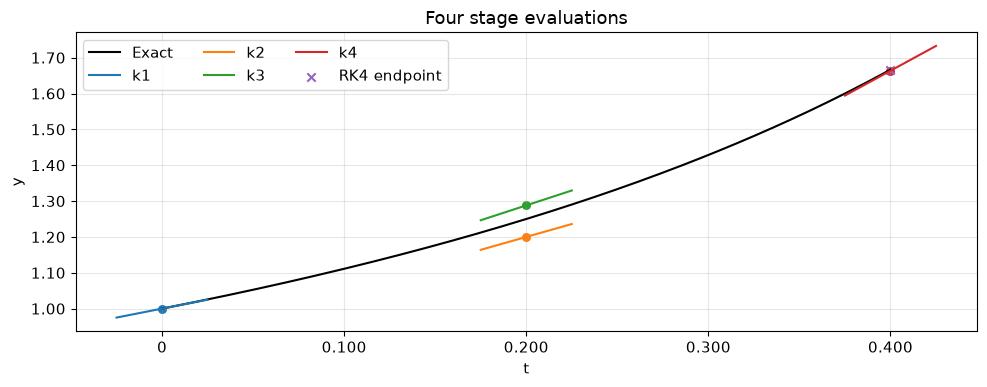

In [3]:
h = 0.400
f_stage = lambda t, y: y**2
k = rk4_stages(f_stage, 0, 1, h)
points = [(0, 1), (h / 2, 1 + h * k[0] / 2),
          (h / 2, 1 + h * k[1] / 2), (h, 1 + h * k[2])]
pprint({f"k{i}": sig3(value) for i, value in enumerate(k, 1)})
fig, ax = plt.subplots()
t = np.linspace(0, h, 200)
ax.plot(t, 1 / (1 - t), color="black", label="Exact")
for i, ((ti, yi), ki) in enumerate(zip(points, k), 1):
    dt = np.array([-1, 1]) * h / 16
    ax.plot(ti + dt, yi + ki * dt, label=f"k{i}")
    ax.scatter(ti, yi, s=30)
ax.scatter(h, rk4(f_stage, 0, 1, h), marker="x", label="RK4 endpoint")
ax.set(xlabel="t", ylabel="y", title="Four stage evaluations")
ax.legend(ncol=3)
save_plot(fig, "01_stages")

## 2. 厳密解を4次まで展開する
時間に依存しない連立方程式$\mathbf y'=\mathbf F(\mathbf y)$から考える。時間依存がある場合も、

$$
\mathbf z=\begin{pmatrix}t\\\mathbf y\end{pmatrix},\qquad
\mathbf z'=\begin{pmatrix}1\\\mathbf f(t,\mathbf y)\end{pmatrix}
$$

と置けば同じ形になる。RK4の各段の時刻も$0,h/2,h/2,h$だけ進むため、以下の議論が使える。

解の近傍で$\mathbf F$が十分滑らかで、必要な導関数が有界であるとする。以下の量はすべてステップの始点で評価する。

$$
\mathbf g=\mathbf F(\mathbf y),\quad \mathbf J=D\mathbf F(\mathbf y),\quad
\mathcal H=D^2\mathbf F(\mathbf y),\quad \mathcal T=D^3\mathbf F(\mathbf y).
$$

$\mathbf J$はJacobi行列、$\mathcal H$と$\mathcal T$はそれぞれ2個、3個のベクトルを受け取る多重線形写像である。例えば$\mathcal H(\mathbf u,\mathbf v)$の第$i$成分は$\sum_{j,k}\partial_{jk}F_i\,u_jv_k$となる。積の微分と連鎖律を使うと、

$$
\begin{aligned}
\mathbf y'&=\mathbf g,\\
\mathbf y''&=\mathbf J\mathbf g,\\
\mathbf y^{(3)}&=\mathcal H(\mathbf g,\mathbf g)+\mathbf J^2\mathbf g,\\
\frac{d}{dt}\mathcal H(\mathbf g,\mathbf g)
 &=\mathcal T(\mathbf g,\mathbf g,\mathbf g)+2\mathcal H(\mathbf g,\mathbf J\mathbf g),\\
\frac{d}{dt}(\mathbf J^2\mathbf g)
 &=\mathcal H(\mathbf g,\mathbf J\mathbf g)
 +\mathbf J\mathcal H(\mathbf g,\mathbf g)+\mathbf J^3\mathbf g.
\end{aligned}
$$

最後の2行を足して$\mathbf y^{(4)}$を求め、Taylor展開に代入する。

$$
\begin{aligned}
\mathbf y(t+h)={}&\mathbf y+h\mathbf g+\frac{h^2}{2}\mathbf J\mathbf g\\
&+\frac{h^3}{6}\{\mathcal H(\mathbf g,\mathbf g)+\mathbf J^2\mathbf g\}\\
&+\frac{h^4}{24}\{\mathcal T(\mathbf g,\mathbf g,\mathbf g)
 +3\mathcal H(\mathbf g,\mathbf J\mathbf g)\\
&\hspace{22mm}+\mathbf J\mathcal H(\mathbf g,\mathbf g)+\mathbf J^3\mathbf g\}+O(h^5).
\end{aligned}
$$

## 3. RK4の各段を展開する
状態の変化を$\mathbf d$と書くと、関数自体の展開は次の形になる。

$$
\mathbf F(\mathbf y+\mathbf d)=\mathbf g+\mathbf J\mathbf d
+\frac12\mathcal H(\mathbf d,\mathbf d)
+\frac16\mathcal T(\mathbf d,\mathbf d,\mathbf d)+O(\|\mathbf d\|^4).
$$

$\mathbf d_2=h\mathbf g/2$を代入すれば第2段が得られる。

$$
\mathbf k_2=\mathbf g+\frac h2\mathbf J\mathbf g
+\frac{h^2}{8}\mathcal H(\mathbf g,\mathbf g)
+\frac{h^3}{48}\mathcal T(\mathbf g,\mathbf g,\mathbf g)+O(h^4).
$$

第3段では$\mathbf d_3=h\mathbf k_2/2$であり、

$$
\mathbf d_3=\frac h2\mathbf g+\frac{h^2}{4}\mathbf J\mathbf g
+\frac{h^3}{16}\mathcal H(\mathbf g,\mathbf g)+O(h^4).
$$

例えば2次の項は、対称性$\mathcal H(\mathbf u,\mathbf v)=\mathcal H(\mathbf v,\mathbf u)$から、

$$
\begin{aligned}
\frac12\mathcal H(\mathbf d_3,\mathbf d_3)
&=\frac12\left\{\frac{h^2}{4}\mathcal H(\mathbf g,\mathbf g)
 +2\frac h2\frac{h^2}{4}\mathcal H(\mathbf g,\mathbf J\mathbf g)\right\}+O(h^4)\\
&=\frac{h^2}{8}\mathcal H(\mathbf g,\mathbf g)
 +\frac{h^3}{8}\mathcal H(\mathbf g,\mathbf J\mathbf g)+O(h^4).
\end{aligned}
$$

1次、3次の項も代入すると、

$$
\begin{aligned}
\mathbf k_3={}&\mathbf g+\frac h2\mathbf J\mathbf g
+h^2\left\{\frac14\mathbf J^2\mathbf g+\frac18\mathcal H(\mathbf g,\mathbf g)\right\}\\
&+h^3\left\{\frac1{16}\mathbf J\mathcal H(\mathbf g,\mathbf g)
+\frac18\mathcal H(\mathbf g,\mathbf J\mathbf g)
+\frac1{48}\mathcal T(\mathbf g,\mathbf g,\mathbf g)\right\}+O(h^4).
\end{aligned}
$$

第4段では、

$$
\mathbf d_4=h\mathbf k_3=h\mathbf g+\frac{h^2}{2}\mathbf J\mathbf g
+h^3\left\{\frac14\mathbf J^2\mathbf g+\frac18\mathcal H(\mathbf g,\mathbf g)\right\}+O(h^4).
$$

代入する3つの項を分けて計算する。

$$
\begin{aligned}
\mathbf J\mathbf d_4&=h\mathbf J\mathbf g+\frac{h^2}{2}\mathbf J^2\mathbf g
+h^3\left\{\frac14\mathbf J^3\mathbf g+\frac18\mathbf J\mathcal H(\mathbf g,\mathbf g)\right\}+O(h^4),\\
\frac12\mathcal H(\mathbf d_4,\mathbf d_4)&=\frac{h^2}{2}\mathcal H(\mathbf g,\mathbf g)
+\frac{h^3}{2}\mathcal H(\mathbf g,\mathbf J\mathbf g)+O(h^4),\\
\frac16\mathcal T(\mathbf d_4,\mathbf d_4,\mathbf d_4)&=\frac{h^3}{6}\mathcal T(\mathbf g,\mathbf g,\mathbf g)+O(h^4).
\end{aligned}
$$

これらと$\mathbf g$を足すと、

$$
\begin{aligned}
\mathbf k_4={}&\mathbf g+h\mathbf J\mathbf g
+h^2\left\{\frac12\mathbf J^2\mathbf g+\frac12\mathcal H(\mathbf g,\mathbf g)\right\}\\
&+h^3\left\{\frac14\mathbf J^3\mathbf g+\frac18\mathbf J\mathcal H(\mathbf g,\mathbf g)
+\frac12\mathcal H(\mathbf g,\mathbf J\mathbf g)
+\frac16\mathcal T(\mathbf g,\mathbf g,\mathbf g)\right\}+O(h^4).
\end{aligned}
$$

$\mathbf k_1=\mathbf g$と合わせて重みを掛ける。更新量に現れる各項の係数は次のとおりである。

$$
\begin{array}{c|c|c}
\text{項}&\text{RK4の係数}&\text{厳密解の係数}\\ \hline
h\mathbf g&(1+2+2+1)/6=1&1\\
h^2\mathbf J\mathbf g&(2/2+2/2+1)/6=1/2&1/2\\
h^3\mathcal H(\mathbf g,\mathbf g)&(2/8+2/8+1/2)/6=1/6&1/6\\
h^3\mathbf J^2\mathbf g&(2/4+1/2)/6=1/6&1/6\\
h^4\mathcal T(\mathbf g,\mathbf g,\mathbf g)&(2/48+2/48+1/6)/6=1/24&1/24\\
h^4\mathcal H(\mathbf g,\mathbf J\mathbf g)&(2/8+1/2)/6=1/8&3/24\\
h^4\mathbf J\mathcal H(\mathbf g,\mathbf g)&(2/16+1/8)/6=1/24&1/24\\
h^4\mathbf J^3\mathbf g&(1/4)/6=1/24&1/24
\end{array}
$$

全項が一致した。RK4の1ステップ写像を$\Phi_h$とすると、厳密値から出発したときの差は次の次数になる。

In [4]:
display(Latex(
    r"\(\displaystyle \boxed{\mathbf y(t+h)-\Phi_h(t,\mathbf y(t))=O(h^5)}\)"
))

<IPython.core.display.Latex object>

## 4. 全体の誤差はなぜ4次なのか
ここでは$h$で割る前の1ステップの差を局所誤差と呼ぶ。文献によっては、この差を$h$で割った量を局所打切り誤差と呼ぶので、定義を確認する必要がある。

$\mathbf e_n=\mathbf y(t_n)-\mathbf y_n$と置く。局所誤差のノルムを$Ch^5$以下とし、十分小さい$h$に対して$\Phi_h$のLipschitz定数を$1+Lh$以下とする。$L>0$は$h$によらない定数である。

$$
\begin{aligned}
\mathbf e_{n+1}&=\mathbf y(t_{n+1})-\Phi_h(t_n,\mathbf y(t_n))\\
&\quad+\Phi_h(t_n,\mathbf y(t_n))-\Phi_h(t_n,\mathbf y_n),\\
\|\mathbf e_{n+1}\|&\le Ch^5+(1+Lh)\|\mathbf e_n\|.
\end{aligned}
$$

初期値が正確なら$\mathbf e_0=\mathbf0$である。$Nh=T$を固定して漸化式を繰り返すと、

$$
\begin{aligned}
\|\mathbf e_N\|&\le Ch^5\sum_{j=0}^{N-1}(1+Lh)^j\\
&=Ch^5\frac{(1+Lh)^N-1}{Lh}\\
&\le\frac C L(e^{LT}-1)h^4=O(h^4).
\end{aligned}
$$

これが4次精度の意味である。誤差が$E(h)\approx Kh^4$に従う範囲では、$E(h/2)/E(h)\approx1/16$となる。私は、段数よりこの比率を確認する方が精度を把握しやすいと感じる。

## 5. 線形方程式で数値確認する
$y'=y,\ y(0)=1$では厳密解は$e^t$である。各段を代入すると、

$$
\begin{aligned}
k_1&=y_n,\quad k_2=(1+h/2)y_n,\\
k_3&=(1+h/2+h^2/4)y_n,\\
k_4&=(1+h+h^2/2+h^3/4)y_n,\\
y_{n+1}&=R(h)y_n,\quad R(h)=1+h+\frac{h^2}{2}+\frac{h^3}{6}+\frac{h^4}{24}.
\end{aligned}
$$

指数関数の4次までと一致する。ただし、この線形例だけでは非線形項の一致は証明できない。上の展開が必要になる。

In [5]:
z = sp.symbols("z")
R = sp.expand(rk4(lambda t, y: y, 0, sp.Integer(1), z))
assert R == sum(z**j / sp.factorial(j) for j in range(5))
# 数式は文字列でprintせず、LaTeXとして表示する。
display(Latex(r"\(\displaystyle R(z)=" + sp.latex(R) + r"\)"))
display(Latex(r"\(\displaystyle e^z-R(z)="
              + sp.latex(sp.series(sp.exp(z) - R, z, 0, 7)) + r"\)"))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

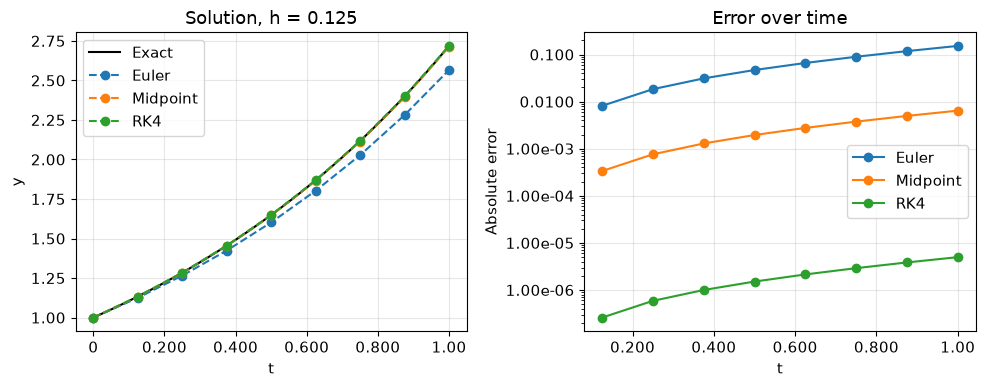

In [6]:
f_linear = lambda t, y: y
methods = {"Euler": euler, "Midpoint": midpoint, "RK4": rk4}
fig, axes = plt.subplots(1, 2)
dense = np.linspace(0, 1, 200)
axes[0].plot(dense, np.exp(dense), "k-", label="Exact")
for name, step in methods.items():
    t, y = solve(step, f_linear, 1, 1, 8)
    axes[0].plot(t, y, "o--", label=name)
    axes[1].semilogy(t[1:], abs(y[1:] - np.exp(t[1:])), "o-", label=name)
for ax in axes:
    ax.set(xlabel="t")
    ax.legend()
axes[0].set(ylabel="y", title="Solution, h = 0.125")
axes[1].set(ylabel="Absolute error", title="Error over time")
save_plot(fig, "02_linear_solution")

終点$T=1$の誤差を$E(h)$として、観測次数$p=\log_2(E(h)/E(h/2))$を計算する。局所誤差は毎回$y(0)=1$から1ステップだけ進めて測る。グラフの破線は比較用の$h^4$と$h^5$である。

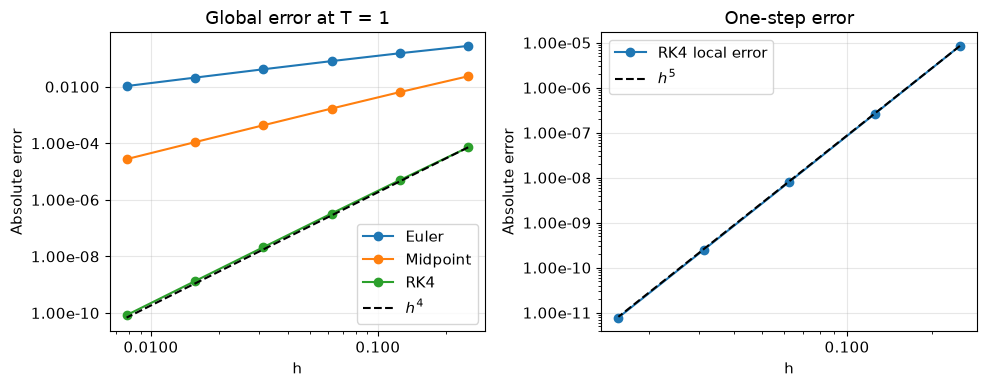

[{'RK4 error': '7.19e-05', 'h': '0.250'},
 {'RK4 error': '4.98e-06', 'h': '0.125'},
 {'RK4 error': '3.28e-07', 'h': '0.0625'},
 {'RK4 error': '2.10e-08', 'h': '0.0312'},
 {'RK4 error': '1.33e-09', 'h': '0.0156'},
 {'RK4 error': '8.38e-11', 'h': '7.81e-03'}]
{'Euler': '0.990', 'Midpoint': '1.99', 'RK4': '3.99'}
{'RK4 error ratio': '15.9', 'local order': '5.00'}


In [7]:
ns = 2 ** np.arange(2, 8)
hs = 1 / ns
errors = {}
fig, axes = plt.subplots(1, 2)
for name, step in methods.items():
    errors[name] = np.array([
        abs(solve(step, f_linear, 1, 1, int(n))[1][-1] - np.e) for n in ns
    ])
    axes[0].loglog(hs, errors[name], "o-", label=name)
# 局所誤差は差し引きの丸め誤差を避けるため、h >= 1/64を使う。
local_h = hs[:-1]
local = np.array([abs(np.exp(h) - rk4(f_linear, 0, 1, h)) for h in local_h])
axes[1].loglog(local_h, local, "o-", label="RK4 local error")
axes[0].loglog(hs, errors["RK4"][0] * (hs / hs[0])**4, "k--", label="$h^4$")
axes[1].loglog(local_h, local[0] * (local_h / local_h[0])**5, "k--", label="$h^5$")
for ax, title in zip(axes, ["Global error at T = 1", "One-step error"]):
    ax.set(xlabel="h", ylabel="Absolute error", title=title)
    ax.legend()
save_plot(fig, "03_convergence")
pprint([{"h": sig3(h), "RK4 error": sig3(error)}
        for h, error in zip(hs, errors["RK4"])])
pprint({name: sig3(np.log2(err[-2] / err[-1])) for name, err in errors.items()})
pprint({"local order": sig3(np.log2(local[-2] / local[-1])),
        "RK4 error ratio": sig3(errors["RK4"][-2] / errors["RK4"][-1])})
assert abs(np.log2(errors["RK4"][-2] / errors["RK4"][-1]) - 4) < 0.0500

## 6. 非線形・時間依存の方程式
$y'=2ty^2,\ y(0)=1$を使う。変数分離から、

$$
\frac{dy}{y^2}=2t\,dt,\quad -\frac1y=t^2+C,\quad C=-1,\quad y(t)=\frac1{1-t^2}.
$$

$t=1$で発散するため、$T=0.500$までで比較する。右図で誤差が$h^4$に近づくことを確認する。

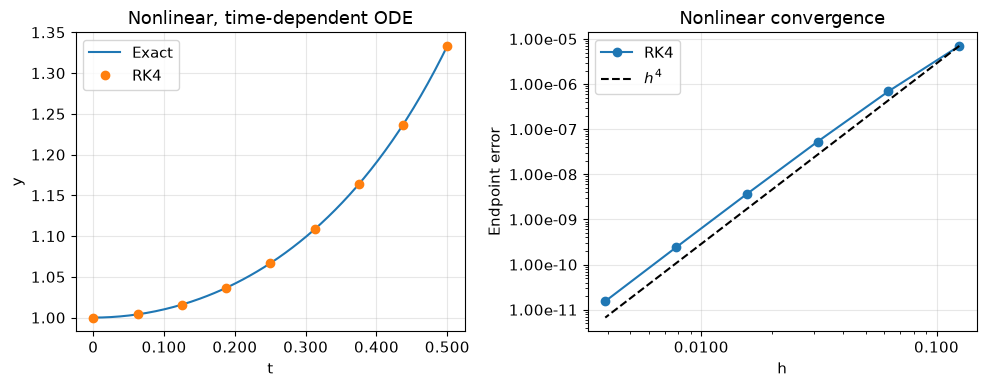

{'nonlinear order': '3.97'}


In [8]:
f_nonlin = lambda t, y: 2 * t * y**2
end = 0.500
t, y = solve(rk4, f_nonlin, 1, end, 8)
hn = end / ns
en = np.array([abs(solve(rk4, f_nonlin, 1, end, int(n))[1][-1]
                   - 1 / (1 - end**2)) for n in ns])
fig, axes = plt.subplots(1, 2)
dense = np.linspace(0, end, 200)
axes[0].plot(dense, 1 / (1 - dense**2), label="Exact")
axes[0].plot(t, y, "o", label="RK4")
axes[0].set(xlabel="t", ylabel="y", title="Nonlinear, time-dependent ODE")
axes[1].loglog(hn, en, "o-", label="RK4")
axes[1].loglog(hn, en[0] * (hn / hn[0])**4, "k--", label="$h^4$")
axes[1].set(xlabel="h", ylabel="Endpoint error", title="Nonlinear convergence")
for ax in axes:
    ax.legend()
save_plot(fig, "04_nonlinear")
pprint({"nonlinear order": sig3(np.log2(en[-2] / en[-1]))})
assert abs(np.log2(en[-2] / en[-1]) - 4) < 0.100

## 7. 連立方程式でも確認する
単振動は$\mathbf y=(q,p)^{\mathsf T}$と置けば、

$$
\mathbf y'=\begin{pmatrix}0&1\\-1&0\end{pmatrix}\mathbf y,\qquad
\mathbf y(0)=\begin{pmatrix}1\\0\end{pmatrix},\qquad
\mathbf y(t)=\begin{pmatrix}\cos t\\-\sin t\end{pmatrix}
$$

となる。終点$T=2\pi$で2成分の誤差のEuclidノルムを測る。左図は位相平面、右図は刻み幅と誤差の関係である。

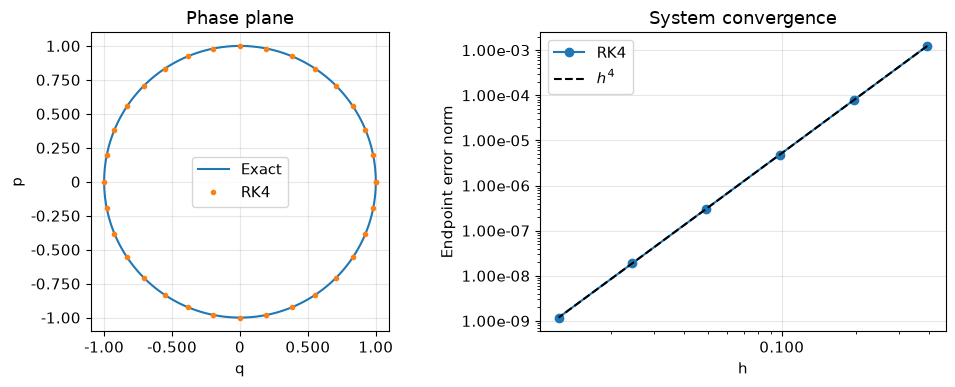

{'system order': '4.00'}


In [9]:
A = np.array([[0, 1], [-1, 0]])
f_vector = lambda t, y: A @ y
end = 2 * np.pi
nv = 2 ** np.arange(4, 10)
hv = end / nv
exact_end = np.array([np.cos(end), -np.sin(end)])
ev = np.array([np.linalg.norm(solve(rk4, f_vector, [1, 0], end, int(n))[1][-1]
                              - exact_end) for n in nv])
t, y = solve(rk4, f_vector, [1, 0], end, 32)
fig, axes = plt.subplots(1, 2)
dense = np.linspace(0, end, 200)
axes[0].plot(np.cos(dense), -np.sin(dense), label="Exact")
axes[0].plot(y[:, 0], y[:, 1], "o", markersize=3, label="RK4")
axes[0].set(xlabel="q", ylabel="p", title="Phase plane", aspect="equal")
axes[1].loglog(hv, ev, "o-", label="RK4")
axes[1].loglog(hv, ev[0] * (hv / hv[0])**4, "k--", label="$h^4$")
axes[1].set(xlabel="h", ylabel="Endpoint error norm", title="System convergence")
for ax in axes:
    ax.legend()
save_plot(fig, "05_system")
pprint({"system order": sig3(np.log2(ev[-2] / ev[-1]))})
assert abs(np.log2(ev[-2] / ev[-1]) - 4) < 0.0500

## 8. 精度と安定性は別に確認する
$y'=\lambda y$では増幅率が$R(h\lambda)$となる。$\lambda=-1$の場合、$h=2$なら$R(-2)=1/3$、$h=3$なら$R(-3)=11/8>1$である。厳密解が減衰しても、大きな刻み幅では数値解が増大する。

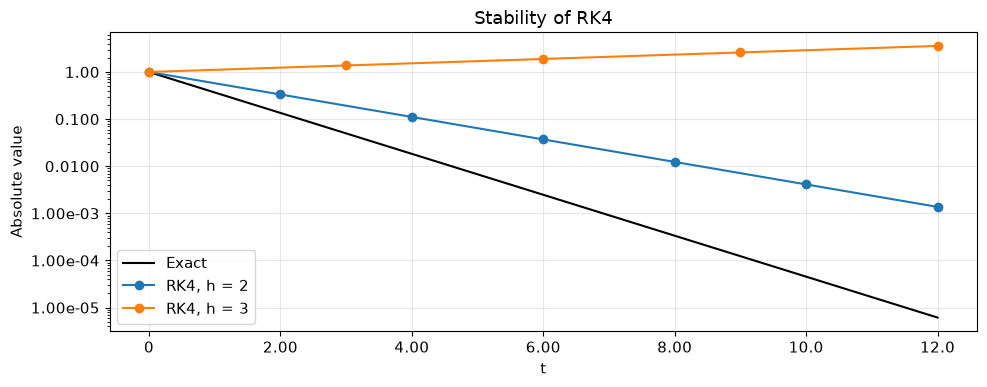

In [10]:
fig, ax = plt.subplots()
dense = np.linspace(0, 12, 300)
ax.semilogy(dense, np.exp(-dense), "k-", label="Exact")
for n in (6, 4):
    t, y = solve(rk4, lambda t, y: -y, 1, 12, n)
    ax.semilogy(t, abs(y), "o-", label=f"RK4, h = {12 // n}")
ax.set(xlabel="t", ylabel="Absolute value", title="Stability of RK4")
ax.legend()
save_plot(fig, "06_stability")

## 結論
この記事では、RK4が厳密解のTaylor展開と4次まで一致し、固定区間の誤差が$O(h^4)$になる理由を示した。

各段の評価位置と重みが非線形項も含めて係数を一致させる。その結果、1ステップの誤差は$O(h^5)$となり、誤差の伝播を含めて評価すると全体は$O(h^4)$となる。数値実験でも、刻み幅を半分にすると終点誤差がおよそ$1/16$になった。

この議論は滑らかな解と固定された有限区間を前提とする。刻み幅が大きすぎる場合の不安定性や、極端に小さい場合の丸め誤差は別に考える必要がある。

参考文献：RK法の4次条件は[Jon Shiach, *Runge–Kutta Methods*, §2.5](https://jonshiach.github.io/ODEs-book/_pages/2.3_RK4_Derivation.html)、局所誤差と大域誤差の関係は[Brenton LeMesurier, *Numerical Methods and Analysis with Python*, §6.4](https://lemesurierb.people.charleston.edu/numerical-methods-and-analysis-python/main/ODE-IVP-3-error-results-one-step-methods.html)を参照できる。